# **DELE CA1 Part A**


WGAN IS NOT FULLY RUN BECAUSE OUT OF TIME


Kazu did initial EDA and preprocessing 

Enzo created the models, DCGAN and WGAN

In [46]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from PIL import Image

from collections import Counter

from scipy.linalg import sqrtm
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

## **Part 2: Exploratory Data Analyis**
---

### 2.1 **Dataset Info** 

In [47]:
# df = pd.read_csv("C:/Users/Enzo/schEnzo/OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")
df = pd.read_csv("C:/Users/tayen\OneDrive - Singapore Polytechnic/Code/DELE/emnist-letters-train.csv")

# Show the first few rows
print(df.head())

# Shape of dataset
print("Shape:", df.shape)  

# Info summary of dataset (columns, non-null counts, datatypes, memory)
print("\n", df.info())

   24    0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.552  0.553  0.554  \
0  -2  142  142  142  142  142  142  142  142  142  ...    142    142    142   
1  15    0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  14    0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  -2  120  120  120  120  120  120  120  120  120  ...    120    120    120   
4  -1  131  131  131  131  131  131  131  131  200  ...    131    131    131   

   0.555  0.556  0.557  0.558  0.559  0.560  0.561  
0    142    142    142    142    142    142    142  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3    120    120    120    120    120    120    120  
4    131    131    131    131    131    131    131  

[5 rows x 785 columns]
Shape: (64828, 785)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64828 entries, 0 to 64827
Columns: 785 entries, 24 to 0.561
dtypes: int64(785)
memory usage: 388.3 MB

 Non

### 2.2 **Class Distribution**

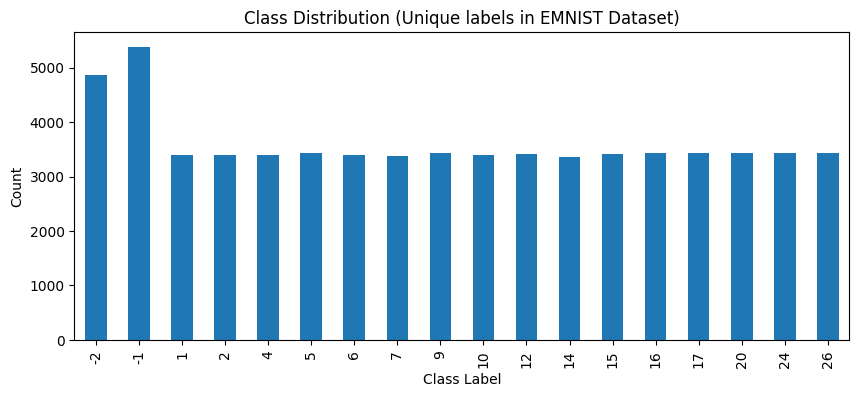

Unique labels in dataset: [-2, -1, 1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26]


In [48]:
labels = df.iloc[:, 0]  # First column is label (1 to 26 for A-Z)

plt.figure(figsize=(10, 4))
labels.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution (Unique labels in EMNIST Dataset)")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

print("Unique labels in dataset:", sorted(df.iloc[:, 0].unique()))

### 2.3 **Sample Images**

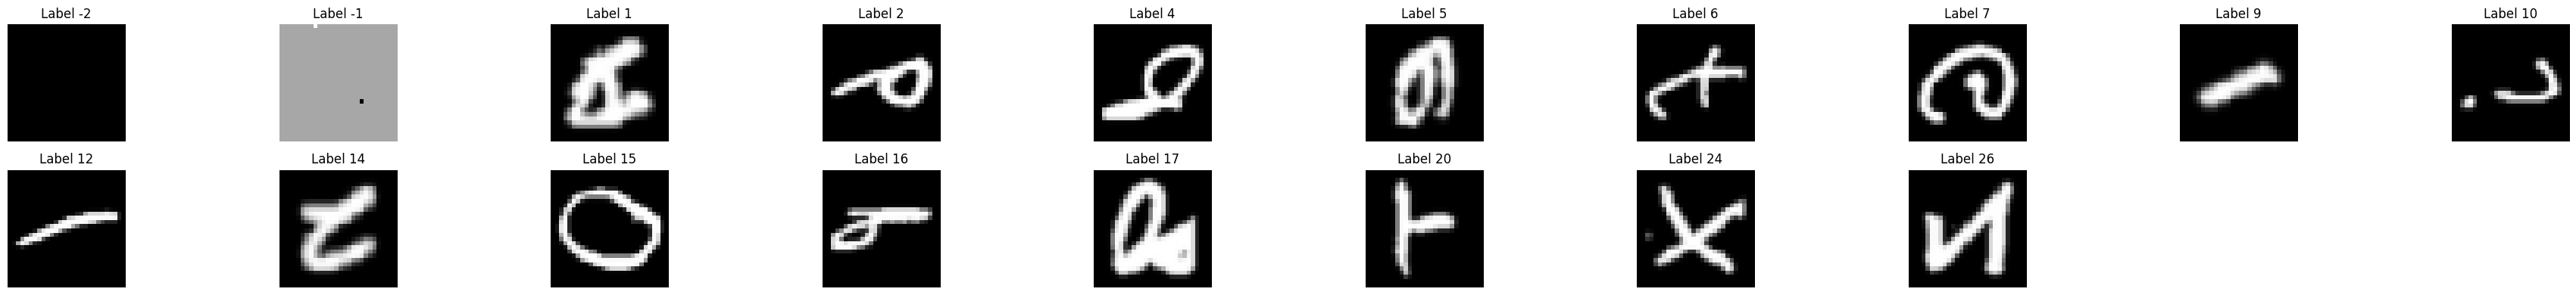

In [49]:
available_labels = sorted(df.iloc[:, 0].unique())

plt.figure(figsize=(len(available_labels) * 2, 4))  # Adjust figure width dynamically
for i, label in enumerate(available_labels):
    img = df[df.iloc[:, 0] == label].iloc[0, 1:].values.reshape(28, 28)
    plt.subplot(2, len(available_labels) // 2 + 1, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

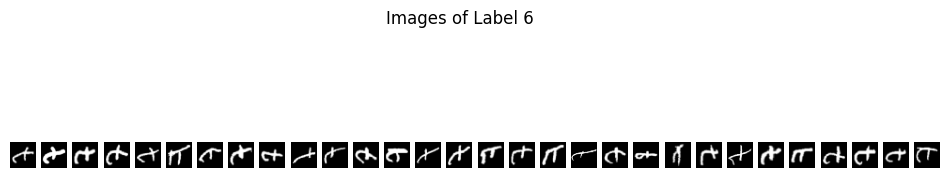

In [50]:
label_to_show = 6
subset = df[df.iloc[:, 0] == label_to_show]

plt.figure(figsize=(12, 3))
for i in range(30):
    img = subset.iloc[i, 1:].values.reshape(28, 28)
    plt.subplot(1, 30, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
plt.suptitle(f"Images of Label {label_to_show}")
plt.show()


In [51]:
labels = df.iloc[:, 0].values

# Filter out invalid labels, e.g. negative values
valid_labels_mask = labels >= 0
labels = labels[valid_labels_mask]

# Extract and reshape image pixels
X_filtered = df.iloc[valid_labels_mask, 1:].values.astype('float32')  # before reshape, for stats

# Compute mean and std before normalization
pixel_mean_raw = X_filtered.mean()
pixel_std_raw = X_filtered.std()
print("Raw pixel mean:", pixel_mean_raw)
print("Raw pixel std:", pixel_std_raw)

# --- Now map numeric labels to letters and index ---

# Manual mapping from numeric label to letter
manual_label_map = {
    1: 'A',
    2: 'B',
    4: 'D',
    5: 'E',
    6: 'F',
    7: 'G',
    9: 'I',
    10: 'J',
    12: 'L',
    14: 'N',
    15: 'O',
    16: 'P',
    17: 'Q',
    20: 'T',
    24: 'X',
    26: 'Z'
}

# Map numeric labels to letter labels
letter_labels = np.array([manual_label_map[label] for label in labels])

# Define fixed letter order for indexing
letters = ['A', 'B', 'D', 'E', 'F', 'G', 'I', 'J', 'L', 'N', 'O', 'P', 'Q', 'T', 'X', 'Z']
letter_to_index = {letter: idx for idx, letter in enumerate(letters)}

# Map letter labels to numeric indices directly (no function)
indexed_labels = np.array([letter_to_index[letter] for letter in letter_labels])

# Print the mapping dictionary only
print("Manual letter_to_index mapping:", letter_to_index)

Raw pixel mean: 43.943172
Raw pixel std: 84.49391
Manual letter_to_index mapping: {'A': 0, 'B': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'I': 6, 'J': 7, 'L': 8, 'N': 9, 'O': 10, 'P': 11, 'Q': 12, 'T': 13, 'X': 14, 'Z': 15}


In [52]:
# Normalize to [-1, 1] for GANs
X_filtered = (X_filtered - 127.5) / 127.5

X_filtered = X_filtered.reshape(-1, 28, 28, 1)

# Sanity checke)
print("Pixel mean:", X_filtered.mean())
print("Pixel std:", X_filtered.std())

Pixel mean: -0.65534747
Pixel std: 0.6626988


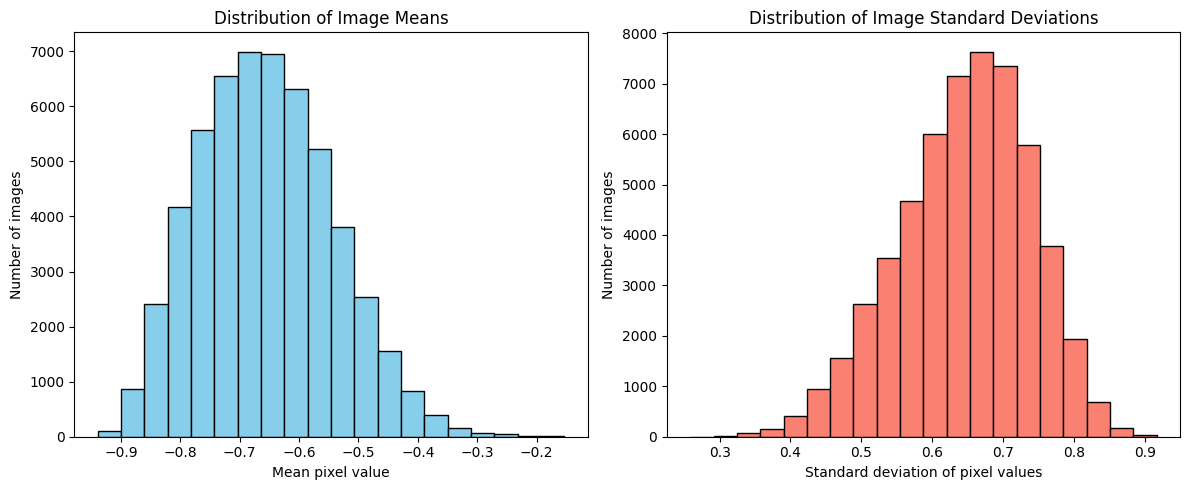

In [53]:
image_means = X_filtered.reshape(X_filtered.shape[0], -1).mean(axis=1)
image_stds = X_filtered.reshape(X_filtered.shape[0], -1).std(axis=1)
plt.figure(figsize=(12, 5))

# Histogram of image means
plt.subplot(1, 2, 1)
plt.hist(image_means, bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Image Means')
plt.xlabel('Mean pixel value')
plt.ylabel('Number of images')

# Histogram of image std deviations
plt.subplot(1, 2, 2)
plt.hist(image_stds, bins=20, color='salmon', edgecolor='black')
plt.title('Distribution of Image Standard Deviations')
plt.xlabel('Standard deviation of pixel values')
plt.ylabel('Number of images')

plt.tight_layout()
plt.show()

In [54]:
def apply_rotation(images, labels):
    rotated_images = []
    
    # Labels that need 90° CW rotation and flip
    rotate_and_flip_labels = {1, 2, 4, 5, 6, 7, 9, 10, 12, 14, 15, 16, 17, 20, 24, 26}

    for img, label in zip(images, labels):
        img = img.reshape(28, 28)
        
        if label in rotate_and_flip_labels:
            img = np.rot90(img, k=3)      # 90° clockwise
            img = np.fliplr(img)         # Flip left-right

        rotated_images.append(img)
    
    rotated_images = np.array(rotated_images).astype('float32')
    rotated_images = np.expand_dims(rotated_images, -1)  # Add channel dimension for grayscale
    return rotated_images

# Apply rotation + flip
X_filtered = apply_rotation(X_filtered, labels)

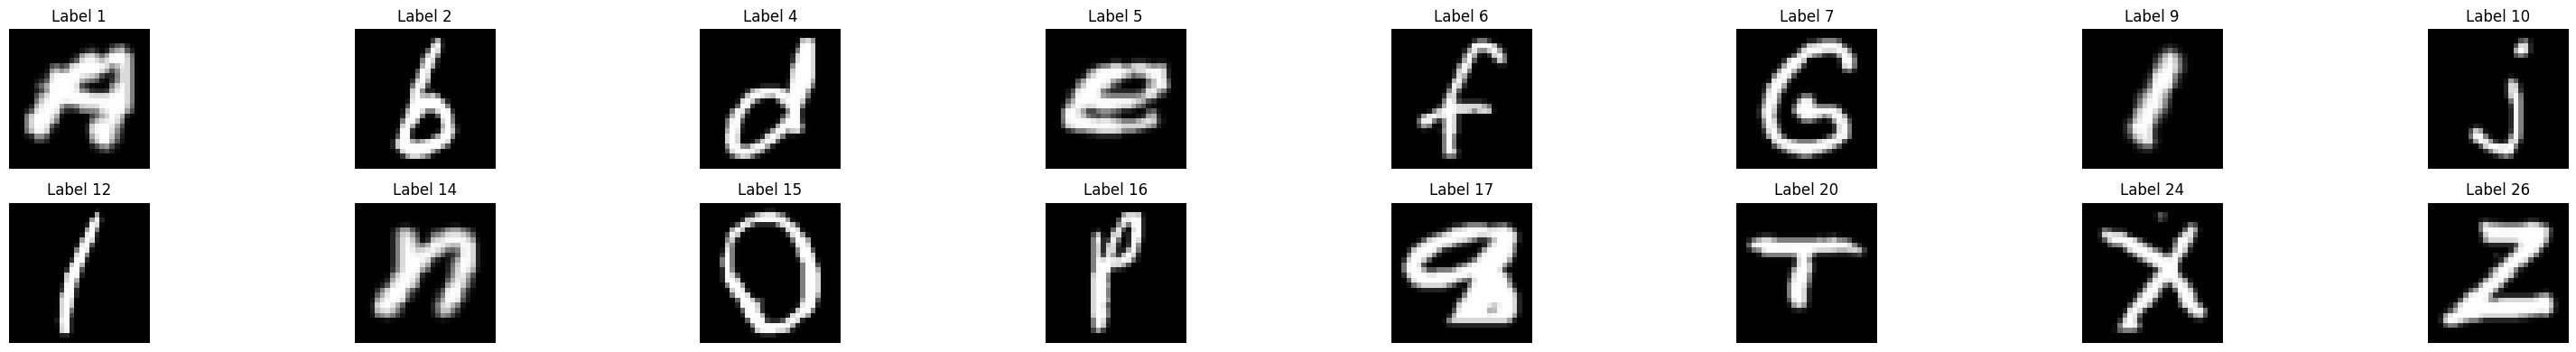

In [55]:
available_labels = sorted(np.unique(labels))

plt.figure(figsize=(len(available_labels) * 2, 4))  # Dynamic width based on number of labels

for i, label in enumerate(available_labels):
    # Find the first image index with this label
    idx = np.where(labels == label)[0][0]
    img = X_filtered[idx].reshape(28, 28)
    
    plt.subplot(2, (len(available_labels) + 1) // 2, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"Label {label}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [56]:
BUFFER_SIZE = 10000
BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(X_filtered) \
    .shuffle(BUFFER_SIZE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# # Split before creating tf.data.Dataset 
# X_train, X_val, y_train, y_val = train_test_split(
#     X_filtered, mapped_labels, test_size=0.2, random_state=42, stratify=mapped_labels
# )

# # Create tf.data.Dataset objects
# train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
# val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
# NOT SURE IF SHOULD SPLIT DATAAAAAA 

In [57]:
def calculate_precision_recall(discriminator, real_images, fake_images, threshold=0.5):
    # Get discriminator scores
    real_scores = discriminator(real_images, training=False)
    fake_scores = discriminator(fake_images, training=False)

    all_scores = tf.concat([real_scores, fake_scores], axis=0)
    min_score = tf.reduce_min(all_scores)
    max_score = tf.reduce_max(all_scores)

    real_probs = (real_scores - min_score) / (max_score - min_score + 1e-8)
    fake_probs = (fake_scores - min_score) / (max_score - min_score + 1e-8)

    # Now apply threshold
    real_preds = tf.cast(real_probs > 0.5, tf.int32)
    fake_preds = tf.cast(fake_probs < 0.5, tf.int32)


    # Precision = TP / (TP + FP)
    # TP: fake images correctly classified as fake (discriminator predicts fake -> 0)
    # but usually in GAN precision/recall are adapted as:
    # Precision = (# fake images predicted fake) / (# total predicted fake)
    # For simplicity:
    TP = np.sum(fake_preds == False)  # Fake images predicted as fake
    FP = np.sum(real_preds == False)  # Real images predicted as fake (false positive)
    precision = TP / (TP + FP + 1e-8)

    # Recall = TP / (TP + FN)
    FN = np.sum(fake_preds == True)   # Fake images predicted as real (false negative)
    recall = TP / (TP + FN + 1e-8)

    return precision, recall

In [58]:
# USES FID ONLY FOR EVALUATION

# Load Inception model once globally
inception_model = InceptionV3(include_top=False, pooling='avg', input_shape=(299, 299, 3))

def resize_and_rgb(images, size=299):
    resized = []
    for img in images:
        # Convert Tensor to NumPy if needed
        if isinstance(img, tf.Tensor):
            img = img.numpy()
        img_arr = np.squeeze(img)  # Now it's always a NumPy array
        img_pil = Image.fromarray((img_arr * 255).astype(np.uint8))
        img_resized = img_pil.resize((size, size), Image.BILINEAR)
        img_rgb = img_resized.convert('RGB')
        resized.append(np.array(img_rgb))
    return np.array(resized)
def preprocess_images_for_inception(images):
    # images expected shape: (N,H,W,3) scaled 0-1 float32
    return preprocess_input(images * 255.0)

def get_activations(images, model=inception_model, batch_size=10):
    activations = []
    n_batches = int(np.ceil(len(images) / batch_size))
    for i in range(n_batches):
        batch = images[i * batch_size:(i + 1) * batch_size]
        batch_pp = preprocess_images_for_inception(batch)
        act = model(batch_pp)
        activations.append(act.numpy())
    return np.vstack(activations)

def calculate_fid(real_images, generated_images):
    act1 = get_activations(real_images)
    act2 = get_activations(generated_images)

    mu1, sigma1 = act1.mean(axis=0), np.cov(act1, rowvar=False)
    mu2, sigma2 = act2.mean(axis=0), np.cov(act2, rowvar=False)

    ssdiff = np.sum((mu1 - mu2)**2)
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = ssdiff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return fid

In [59]:
def compute_intra_class_fid(real_images, real_labels, fake_images, fake_labels, resize_and_rgb, calculate_fid):
    unique_labels = np.unique(real_labels)
    fid_scores = []
    
    for label in unique_labels:
        # Select images of this class
        real_class_images = real_images[real_labels == label]
        fake_class_images = fake_images[fake_labels == label]

        # Skip if no fake images for this class
        if len(fake_class_images) == 0:
            continue
        
        # Prepare images for FID (resize, convert to RGB if needed)
        real_prepped = resize_and_rgb(real_class_images)
        fake_prepped = resize_and_rgb(fake_class_images)
        
        fid = calculate_fid(real_prepped, fake_prepped)
        fid_scores.append(fid)
    
    if len(fid_scores) == 0:
        return None
    
    # Return average intra-class FID
    return np.mean(fid_scores)

In [60]:
def plot_tsne(real_images, fake_images, title="t-SNE"):
    real_flat = real_images.reshape(len(real_images), -1)
    fake_flat = fake_images.reshape(len(fake_images), -1)
    X = np.concatenate([real_flat, fake_flat], axis=0)
    y = np.array([0]*len(real_flat) + [1]*len(fake_flat))

    X_embedded = TSNE(n_components=2, perplexity=30, learning_rate=200, init='pca', random_state=42).fit_transform(X)

    plt.figure(figsize=(6, 6))
    plt.scatter(X_embedded[y==0, 0], X_embedded[y==0, 1], c='blue', label='Real', alpha=0.5)
    plt.scatter(X_embedded[y==1, 0], X_embedded[y==1, 1], c='red', label='Fake', alpha=0.5)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [61]:
def save_metrics_to_file(filename, epoch, gen_loss, disc_loss, precision, recall, fid_score, intra_fid_score=None, model_type="model"):
    os.makedirs("checkpoints", exist_ok=True)
    full_filename = f"checkpoints/{model_type}_{filename}"
    with open(full_filename, "a") as f:
        f.write(f"Epoch {epoch + 1}:\n")
        f.write(f"Generator Loss: {gen_loss:.4f}\n")
        f.write(f"Discriminator Loss: {disc_loss:.4f}\n")
        f.write(f"Precision: {precision:.4f}, Recall: {recall:.4f}\n")
        f.write(f"FID: {fid_score:.4f}\n")
        if intra_fid_score is not None:
            f.write(f"Intra-class FID: {intra_fid_score:.4f}\n")
        f.write("--------\n")


def save_generated_images(generator, epoch, noise_dim=100, num_images=49, model_type="model"):
    os.makedirs("generated_images", exist_ok=True)
    noise = tf.random.normal([num_images, noise_dim])
    generated_images = generator(noise, training=False)
    generated_images = (generated_images + 1.0) / 2.0  # rescale from [-1,1] to [0,1]

    import matplotlib.pyplot as plt
    fig = plt.figure(figsize=(7, 7))
    for i in range(num_images):
        plt.subplot(7, 7, i + 1)
        plt.imshow(generated_images[i, :, :, 0], cmap='gray')
        plt.axis('off')

    plt.tight_layout()
    filename = f"generated_images/{model_type}_epoch_{epoch + 1}.png"
    plt.savefig(filename)
    plt.close()

In [62]:
def plot_tsne_evaluation(generator, real_images, noise_dim, epoch=None, num_samples=50):

    def to_numpy(x):
        return x.numpy() if hasattr(x, 'numpy') else x

    # Generate fake images for t-SNE
    tsne_noise = tf.random.normal([num_samples, noise_dim])
    tsne_fake_images = generator(tsne_noise, training=False)
    tsne_fake_images = (tsne_fake_images + 1) / 2.0  # Rescale to [0,1]

    tsne_real_images = real_images[:num_samples]
    tsne_real_images = (tsne_real_images + 1) / 2.0 if tsne_real_images.min() < 0 else tsne_real_images / 255.0

    # Flatten images for t-SNE
    tsne_real_flat = to_numpy(tsne_real_images).reshape(num_samples, -1)
    tsne_fake_flat = to_numpy(tsne_fake_images).reshape(num_samples, -1)

    # Combine and create labels (0=real,1=fake)
    X = np.vstack([tsne_real_flat, tsne_fake_flat])
    y = np.array([0]*num_samples + [1]*num_samples)

    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_embedded = tsne.fit_transform(X)

    plt.figure(figsize=(8,6))
    plt.scatter(X_embedded[y == 0, 0], X_embedded[y == 0, 1], label='Real', alpha=0.5)
    plt.scatter(X_embedded[y == 1, 0], X_embedded[y == 1, 1], label='Fake', alpha=0.5)
    plt.title(f"t-SNE Plot")
    plt.legend()
    plt.show()

In [63]:
def plot_metrics_over_epochs(precision_history, recall_history, gen_loss_history, disc_loss_history, model_type="model"):

    epochs = list(range(1, len(precision_history) + 1))
    
    plt.figure(figsize=(14, 6))

    # Precision and Recall subplot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, precision_history, label='Precision', color='blue', marker='o')
    plt.plot(epochs, recall_history, label='Recall', color='green', marker='x')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.title(f'{model_type} - Precision & Recall Over Epochs')
    plt.legend()
    plt.grid(True)

    # Generator and Discriminator Loss subplot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, gen_loss_history, label='Generator Loss', color='red', marker='o')
    plt.plot(epochs, disc_loss_history, label='Discriminator Loss', color='purple', marker='x')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'{model_type} - Generator & Discriminator Loss Over Epochs')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

In [64]:
def evaluate_gan(generator, discriminator, noise_dim, real_images,
                class_labels=None, generated_labels=None, seed_noise=None,
                epoch=None,
                precision_history=None, recall_history=None,
                gen_loss_history=None, disc_loss_history=None):
    # === Generate fake images ===
    if seed_noise is not None:
        noise = seed_noise
    else:
        noise = tf.random.normal([100, noise_dim])
    fake_images = generator(noise, training=False)
    fake_images_scaled = (fake_images + 1) / 2.0  # Rescale from [-1, 1] to [0, 1]

    # === Match real image count ===
    num_fake = fake_images.shape[0]
    real_images = real_images[:num_fake]
    if class_labels is not None:
        class_labels = class_labels[:num_fake]

    # === Discriminator score ===
    disc_scores = discriminator(fake_images, training=False)
    avg_disc_score = tf.reduce_mean(disc_scores).numpy()

    # === Pixel stats ===
    real_scaled = (real_images + 1) / 2.0 if real_images.min() < 0 else real_images / 255.0
    fake_scaled = fake_images_scaled.numpy()
    fake_mean, fake_std = fake_scaled.mean(), fake_scaled.std()
    real_mean, real_std = real_scaled.mean(), real_scaled.std()

    # === FID ===
    real_for_fid = resize_and_rgb(real_scaled)
    fake_for_fid = resize_and_rgb(fake_scaled)
    fid_score = calculate_fid(real_for_fid, fake_for_fid)

    # === Intra-class FID (only if valid labels are available) ===
    if (class_labels is not None and generated_labels is not None
            and len(np.unique(generated_labels)) > 1):
        intra_fid_score = compute_intra_class_fid(
            real_scaled, class_labels, fake_scaled, generated_labels,
            resize_and_rgb, calculate_fid
        )
    else:
        intra_fid_score = None

    # === Precision & Recall ===
    precision, recall = calculate_precision_recall(discriminator, real_images, fake_images)

    # === Log history ===
    if precision_history is not None:
        precision_history.append(precision)
    if recall_history is not None:
        recall_history.append(recall)

    # === Return metrics ===
    return {
        "avg_disc_score": avg_disc_score,
        "real_mean": real_mean,
        "real_std": real_std,
        "fake_mean": fake_mean,
        "fake_std": fake_std,
        "fid_score": fid_score,
        "intra_fid_score": intra_fid_score,
        "precision": precision,
        "recall": recall,
        "fake_images": fake_images,
    }

In [65]:
def show_generated_images(generator, noise_dim, epoch, seed_noise=None):
    if seed_noise is not None:
        noise = seed_noise
    else:
        noise = tf.random.normal([25, noise_dim])

    fake_images = generator(noise, training=False)
    fake_images_scaled = (fake_images + 1) / 2.0

    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(fake_images_scaled[i, :, :, 0], cmap='gray')
        plt.axis('off')
    plt.suptitle(f'Generated Images (Epoch {epoch})')
    plt.tight_layout()
    plt.show()

In [66]:
# === 2. Generator Model ===
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)), 
        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

# === 3. Discriminator Model ===
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

# === 4. Loss & Optimizer ===
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator = make_generator_model()
discriminator = make_discriminator_model()

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [67]:
# === 5. Training Loop ===
EPOCHS = 2
noise_dim = 256
model_type = "DCGAN"

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

# === Seed for evaluation (e.g., t-SNE, metrics) ===
eval_seed = tf.random.normal([1000, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs, real_images, class_labels=None, model_type=model_type):
    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")
        epoch_gen_loss = []
        epoch_disc_loss = []

        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
            epoch_gen_loss.append(gen_loss.numpy())
            epoch_disc_loss.append(disc_loss.numpy())

        avg_gen_loss = np.mean(epoch_gen_loss)
        avg_disc_loss = np.mean(epoch_disc_loss)
        gen_loss_history.append(avg_gen_loss)
        disc_loss_history.append(avg_disc_loss)

        print(f"Generator Loss: {avg_gen_loss:.4f}, Discriminator Loss: {avg_disc_loss:.4f}")

        # === Run evaluation at the end of the epoch ===
        metrics = evaluate_gan(generator, discriminator, noise_dim, real_images, epoch=epoch, seed_noise=eval_seed,
                                precision_history=precision_history, recall_history=recall_history,
                                gen_loss_history=gen_loss_history, disc_loss_history=disc_loss_history)

        # Print results
        print(f"Avg Discriminator Confidence: {metrics['avg_disc_score']:.4f}")
        print(f"Real Images - Mean: {metrics['real_mean']:.4f}, Std: {metrics['real_std']:.4f}")
        print(f"Fake Images - Mean: {metrics['fake_mean']:.4f}, Std: {metrics['fake_std']:.4f}")
        print(f"FID Score: {metrics['fid_score']:.4f}")
        if metrics['intra_fid_score'] is not None:
            print(f"Intra-class FID Score: {metrics['intra_fid_score']:.4f}")
        print(f"Precision: {metrics['precision']:.4f}, Recall: {metrics['recall']:.4f}")

        # === Only save & plot on last epoch ===
        if epoch == epochs - 1:
            
            # Save weights
            generator.save_weights(f"checkpoints/generator_epoch_{epoch + 1}.h5")
            discriminator.save_weights(f"checkpoints/discriminator_epoch_{epoch + 1}.h5")

            # Save metrics including FID and intra FID
            save_metrics_to_file(
                f"metrics_{model_type}_{epoch + 1}.txt",
                epoch,
                avg_gen_loss,
                avg_disc_loss,
                metrics['precision'],
                metrics['recall'],
                metrics['fid_score'],
                metrics['intra_fid_score']
            )

            # Save generated images
            save_generated_images(generator, epoch, noise_dim, model_type=model_type)

            plot_metrics_over_epochs(
                precision_history,
                recall_history,
                gen_loss_history,
                disc_loss_history,
                model_type=model_type
            )

            # Optionally do plots here based on history variables if you want
            plot_tsne_evaluation(generator, real_images, noise_dim, epoch=epochs)

        # Optionally show generated images during training
        show_generated_images(generator, noise_dim, epoch + 1)


    
# Start training
train(train_dataset, EPOCHS, real_images=X_filtered, model_type=model_type)


Epoch 1/2
Generator Loss: 1.7536, Discriminator Loss: 0.7732


ResourceExhaustedError: Exception encountered when calling layer "batch_normalization_292" "                 f"(type BatchNormalization).

{{function_node __wrapped__AddV2_device_/job:localhost/replica:0/task:0/device:GPU:0}} failed to allocate memory [Op:AddV2]

Call arguments received by layer "batch_normalization_292" "                 f"(type BatchNormalization):
  • inputs=tf.Tensor(shape=(1000, 25088), dtype=float32)
  • training=False

In [ ]:
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*512, use_bias=False, input_shape=(256,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 512)),

        layers.Conv2DTranspose(256, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(32, (3, 3), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (3, 3), strides=(1, 1), padding='same', use_bias=False, activation='tanh')
    ])
    return model

In [ ]:
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)  # No activation for WGAN
    ])
    return model

In [ ]:
# === Gradient Penalty ===
def gradient_penalty(discriminator, real_images, fake_images):
    batch_size = real_images.shape[0]
    alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
    interpolated = real_images + alpha * (fake_images - real_images)
    with tf.GradientTape() as tape:
        tape.watch(interpolated)
        pred = discriminator(interpolated, training=True)
    grads = tape.gradient(pred, [interpolated])[0]
    grads = tf.reshape(grads, [batch_size, -1])
    grads_norm = tf.sqrt(tf.reduce_sum(tf.square(grads), axis=1) + 1e-12)
    gp = tf.reduce_mean((grads_norm - 1.0) ** 2)
    return gp

In [ ]:
# === Loss functions ===
def discriminator_loss(real_output, fake_output, gp, lambda_gp=10.0):
    return tf.reduce_mean(fake_output) - tf.reduce_mean(real_output) + lambda_gp * gp

def generator_loss(fake_output):
    return -tf.reduce_mean(fake_output)

In [ ]:
# === Hyperparameters ===
EPOCHS = 40
noise_dim = 256
BATCH_SIZE = 64
CRITIC_ITERATIONS = 5
LAMBDA_GP = 10.0

gen_loss_history = []
disc_loss_history = []
precision_history = []
recall_history = []

# === Optimizers ===
generator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.0, beta_2=0.9)

# === Create models ===
generator = make_generator_model()
discriminator = make_discriminator_model()

# === Seed for evaluation (e.g., t-SNE, metrics) ===
eval_seed = tf.random.normal([1000, noise_dim])

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    # Update discriminator (critic) multiple times
    for _ in range(CRITIC_ITERATIONS):
        noise = tf.random.normal([batch_size, noise_dim])
        with tf.GradientTape() as disc_tape:
            fake_images = generator(noise, training=True)
            real_output = discriminator(real_images, training=True)
            fake_output = discriminator(fake_images, training=True)
            gp = gradient_penalty(discriminator, real_images, fake_images)
            disc_loss = discriminator_loss(real_output, fake_output, gp, LAMBDA_GP)
        gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
        discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    # Update generator once
    noise = tf.random.normal([batch_size, noise_dim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)
    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))

    return gen_loss, disc_loss

def train(dataset, epochs, real_images):
    for epoch in range(epochs):
        print(f"\nEpoch {epoch + 1}/{epochs}")
        epoch_gen_loss = []
        epoch_disc_loss = []

        for image_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch)
            epoch_gen_loss.append(gen_loss.numpy())
            epoch_disc_loss.append(disc_loss.numpy())

        # Record average losses
        avg_gen_loss = np.mean(epoch_gen_loss)
        avg_disc_loss = np.mean(epoch_disc_loss)
        gen_loss_history.append(avg_gen_loss)
        disc_loss_history.append(avg_disc_loss)

        # Evaluate precision & recall
        noise = tf.random.normal([min(256, len(real_images)), noise_dim])
        fake_images = generator(noise, training=False)
        real_subset = real_images[:fake_images.shape[0]]
        precision, recall = calculate_precision_recall(discriminator, real_subset, fake_images)
        precision_history.append(precision)
        recall_history.append(recall)

        print(f"Generator Loss: {avg_gen_loss:.4f}, Discriminator Loss: {avg_disc_loss:.4f}")
        print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")

        # === Only save on last epoch ===
        if epoch == epochs - 1:
            # Save model weights
            generator.save_weights(f"checkpoints/generator_epoch_{epoch + 1}.h5")
            discriminator.save_weights(f"checkpoints/discriminator_epoch_{epoch + 1}.h5")

            # Save evaluation metrics
            save_metrics_to_file(f"metrics_{epoch + 1}.txt", epoch, avg_gen_loss, avg_disc_loss, precision, recall)

            # Save sample images
            save_generated_images(generator, epoch, noise_dim)

            # Optionally show to screen
            show_generated_images(generator, noise_dim, epoch + 1)

    # Run full evaluation after training
    evaluate_gan(generator, discriminator, noise_dim, real_images, epoch=epochs, seed_noise=eval_seed,
                 precision_history=precision_history, recall_history=recall_history,
                 gen_loss_history=gen_loss_history, disc_loss_history=disc_loss_history, model_type="WGAN-GP")

# Start training
train(train_dataset, EPOCHS, real_images=X_filtered)